# Weather Hazard Category · Model comparison and promotion

**36120 Advanced Machine Learning Application** · Assessment Task 2 · Weather Intelligence (Open-Meteo, Sydney)

*Selects one model, evaluates it once on the test split, and promotes it to production*

This is the **only notebook in the project that reads the test split**. It compares every exported WHC experiment on validation, selects one, scores it **once** on the test split, and copies it to `models/weather_hazard/production/` for the FastAPI service.

### Student details

| | |
|:--|:--|
| **Student name** | Juan Vargas T. |
| **Student ID** | 25945320 |
| **Subject** | 36120 Advanced Machine Learning Application |
| **Assessment** | AT2 · Weather Intelligence |
| **GitHub** | [Sebas102507](https://github.com/Sebas102507) |

## Overview

| # | Step | What happens |
|:-:|:--|:--|
| 1 | Discover | Find every exported bundle under `models/weather_hazard/experiments/` |
| 2 | Feature contract | Keep only bundles fitted on the current feature set |
| 3 | Load data | Train, validation and test splits |
| 4 | Validation scores | Score every bundle and every baseline on validation |
| 5 | Select | Apply the selection rule, with baseline and noise checks |
| 6 | Test once | Score the winner on the test split |
| 7 | Promote | Copy the winner to `production/` with an audit record |
| 8 | Conclusions | What to carry into the report |

> **Why this order matters.** Nothing is refitted, so the models scored here are exactly the
> artefacts that would be deployed. Selection uses validation only. The test split is read in
> section 6, after the choice is final, so the test score is an honest estimate of performance on
> unseen dates. The validation score cannot play that role: every experiment tuned against it,
> and this notebook then picked the best of those tuned results.

---
## 0. Setup

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

from nucleus_ml import weather as wx

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

TASK = "weather_hazard"

task = wx.load_task(TASK)
print(f"{task.target_name} | selection metric: {task.metric} | targets: "
      f"{task.target_columns}")

Weather Hazard Category | selection metric: macro_f1 | targets: ['whc_t7']


---
## 1. Discover the exported experiments

Each experiment notebook saved a bundle in `models/weather_hazard/experiments/<experiment>/`. A bundle
listed with no models is a half-written experiment: rerun that notebook before trusting the
comparison, because a missing model is not a model that lost.

In [18]:
bundles = wx.discover_bundles(task)
wx.bundle_inventory(bundles)

,algorithm,models_found,horizons
experiment,,,
whc_dummy,Dummy Classifier,1,[7]
whc_logistic_regression,Multinomial Logistic Regression,1,[7]
whc_mlp,MLP Classifier,1,[7]
whc_random_forest,Random Forest Classifier,1,[7]
whc_xgboost,XGBoost Classifier,1,[7]


---
## 2. Feature-contract check

Every bundle recorded the feature columns it was trained on. A model trained on an older feature
set still loads and predicts, but its scores describe a different information set and cannot be
compared fairly. Such bundles are **excluded**; rerun their notebooks to include them.

In [19]:
contract = wx.check_feature_contract(bundles, task)
usable = contract["matches_current"] & contract["has_models"]
COMPARED = contract.index[usable].tolist()
EXCLUDED = contract.index[~usable].tolist()

if not COMPARED:
    raise RuntimeError("No bundle matches the current feature set. Rerun the experiment notebooks.")
print(f"Compared: {COMPARED}")
print(f"Excluded: {EXCLUDED or 'none'}")
contract

Compared: ['whc_dummy', 'whc_logistic_regression', 'whc_mlp', 'whc_random_forest', 'whc_xgboost']
Excluded: none


,n_features,matches_current,has_models
experiment,,,
whc_dummy,105,True,True
whc_logistic_regression,105,True,True
whc_mlp,105,True,True
whc_random_forest,105,True,True
whc_xgboost,105,True,True


---
## 3. Load the splits

The test split is loaded here to keep data access in one place, but it is **not used until
section 6**.

In [20]:
X, y = wx.load_splits(task, ("train", "val", "test"))

# Classification metrics are averaged over the classes seen in training.
LABELS = sorted(y["train"][task.target_columns[0]].unique()) if task.is_classification else None

pd.DataFrame({split: {"rows": len(X[split]), "start": X[split].index.min().date(),
                      "end": X[split].index.max().date()} for split in X}).T

,rows,start,end
train,2885,2016-01-31,2023-12-24
val,359,2024-01-01,2024-12-24
test,358,2025-01-01,2025-12-24


---
## 4. Score every experiment on validation

Each bundle is loaded and scored on the same validation data with the same metric functions as
the experiment notebooks. Nothing is refitted, so these numbers should reproduce the ones each
notebook reported; a mismatch means that bundle is stale. The baselines are scored alongside as
the bar every model must clear.

Accuracy, balanced accuracy and mean ordinal error are included in the full table for the report,
but only macro F1 decides the ranking.

/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DummyClassifier from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/juanvargas/UTS/3rd Semester/

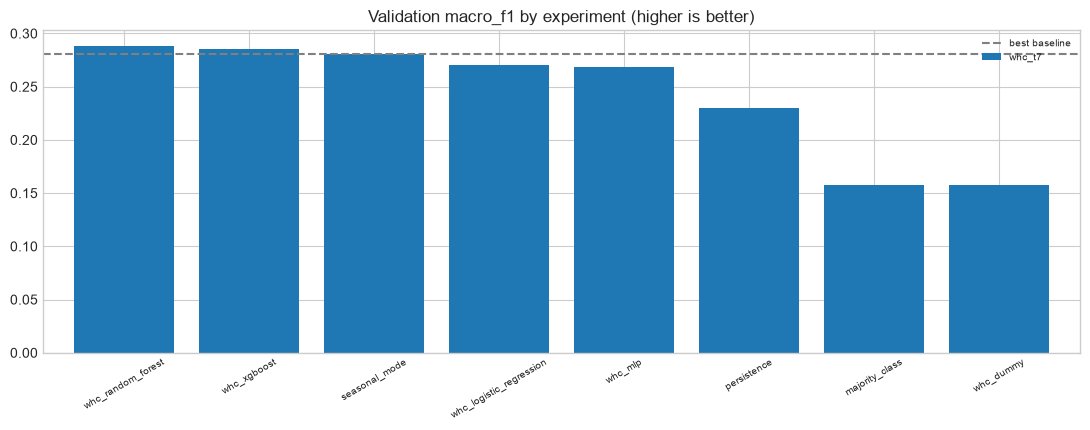

target,whc_t7,score,is_baseline,predicted_classes
experiment,,,,
whc_random_forest,0.288,0.288,False,2
whc_xgboost,0.285,0.285,False,2
seasonal_mode,0.281,0.281,True,2
whc_logistic_regression,0.271,0.271,False,4
whc_mlp,0.269,0.269,False,2
persistence,0.230,0.230,True,3
majority_class,0.157,0.157,True,1
whc_dummy,0.157,0.157,False,1


In [21]:
models, columns, rows = {}, {}, []
for name in COMPARED:
    columns[name] = wx.bundle_feature_columns(bundles[name], task)
    models[name] = wx.load_bundle_models(bundles[name], task.horizons)
    rows += wx.score_models(task, name, models[name], columns[name], X, y, "val", LABELS)
rows += wx.score_baselines(task, X, y, "val", LABELS)

scores = pd.DataFrame(rows)
ranking = wx.rank_experiments(task, scores)

wx.plot_ranking(task, ranking, f"{task.name}-comparison-validation")
plt.show()
ranking

In [22]:
# Full validation metrics for the report.
scores.drop(columns=["split", "is_baseline"]).set_index(["experiment", "target"])

,,accuracy,balanced_accuracy,macro_f1,weighted_f1,mean_ordinal_error,predicted_classes
experiment,target,,,,,,
whc_dummy,whc_t7,0.460,0.333,0.157,0.289,0.582,1
whc_logistic_regression,whc_t7,0.465,0.366,0.271,0.492,0.635,4
whc_mlp,whc_t7,0.526,0.367,0.269,0.515,0.499,2
whc_random_forest,whc_t7,0.565,0.393,0.288,0.553,0.457,2
whc_xgboost,whc_t7,0.560,0.392,0.285,0.546,0.462,2
majority_class,whc_t7,0.460,0.333,0.157,0.289,0.582,1
persistence,whc_t7,0.443,0.307,0.230,0.442,0.607,3
seasonal_mode,whc_t7,0.552,0.386,0.281,0.537,0.479,2


---
## 5. Rank and select

The selection rule is **highest validation macro F1**, fixed **before** looking at the results.

Macro F1 weights every hazard class equally, so the selection cannot be won by a model that only
predicts the common Low Risk days. `predicted_classes` is shown in the ranking: a model predicting
a single class is the majority rule in disguise, whatever its score.

Two checks are made rather than assumed:

- **Against the baselines** — the winner must beat the best baseline on every target.
- **Against noise** — if the margin over the runner-up is smaller than the typical seed spread
  recorded by the experiments, the ranking does not really separate the top two; the report should
  say so and choose on secondary grounds (cost, interpretability, artefact size).

In [23]:
selection = wx.select_best(task, ranking, bundles)
BEST = selection["best"]

print(f"Selected : {BEST} ({task.metric} = {selection['best_score']:.4f})")
print(f"Runner-up: {selection['runner_up']} (margin {selection['margin']:.4f})")
print(f"Typical seed spread: {selection['typical_seed_spread']:.4f}")
for message in selection["warnings"]:
    print(f"WARNING: {message}")

Selected : whc_random_forest (macro_f1 = 0.2884)
Runner-up: whc_xgboost (margin 0.0030)
Typical seed spread: 0.0232


---
## 6. Single test evaluation

The test split is scored **once**, for the selected model and the baselines only. Nothing after
this point changes the selection.

Expect the test score to be somewhat worse than validation: that is the selection optimism being
paid back, not a failure. A small gap suggests a robust selection; a large one suggests the ranking
was fitted to 2024's particular weather and belongs in the limitations section.

> The selected model is **not** refitted on train + validation. Refitting would add a year of
> data, but the promoted artefact would then differ from the one its experiment notebook
> documented and evaluated. Keeping it unchanged keeps the chain from experiment to production
> auditable.

Selection optimism for whc_random_forest (macro_f1):


,validation,test,test_minus_validation
target,,,
whc_t7,0.288,0.276,-0.013


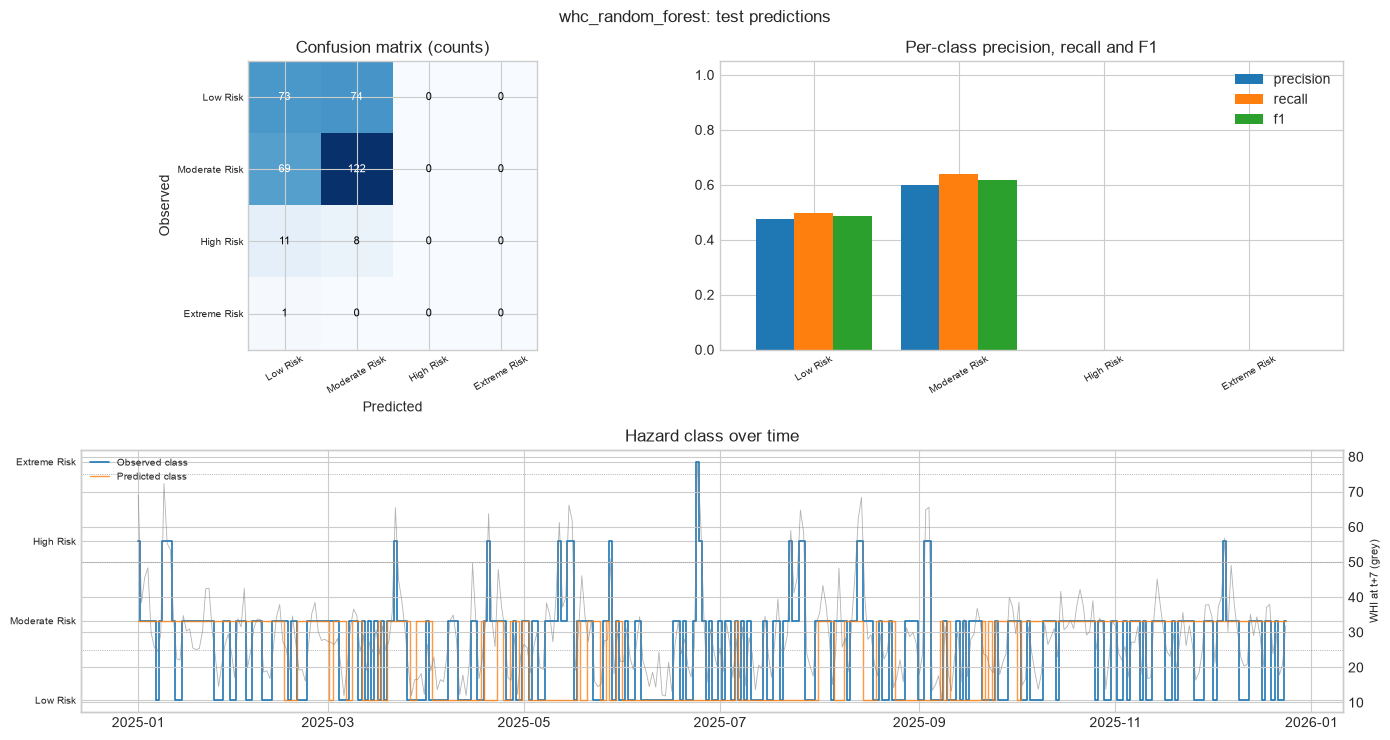

is_baseline  accuracy  balanced_accuracy  macro_f1  \
target experiment                                                              
whc_t7 whc_random_forest        False     0.545              0.284     0.276   
       majority_class            True     0.411              0.250     0.146   
       persistence               True     0.447              0.233     0.233   
       seasonal_mode             True     0.536              0.290     0.276   

                          weighted_f1  mean_ordinal_error  predicted_classes  
target experiment                                                             
whc_t7 whc_random_forest        0.529               0.492                  2  
       majority_class           0.239               0.648                  1  
       persistence              0.448               0.609                  4  
       seasonal_mode            0.521               0.508                  2

In [24]:
test_rows = (wx.score_models(task, BEST, models[BEST], columns[BEST], X, y, "test", LABELS)
             + wx.score_baselines(task, X, y, "test", LABELS))
test_scores = pd.DataFrame(test_rows).drop(columns=["split"]).set_index(["target", "experiment"])

optimism = pd.DataFrame({
    "validation": ranking.loc[BEST, task.target_columns].astype(float),
    "test": test_scores.xs(BEST, level="experiment")[task.metric],
})
optimism["test_minus_validation"] = optimism["test"] - optimism["validation"]
print(f"Selection optimism for {BEST} ({task.metric}):")
display(optimism)

wx.plot_test_predictions(task, models[BEST], columns[BEST], X, y,
                         f"{BEST}: test predictions", f"{task.name}-comparison-test")
plt.show()
test_scores

---
## 7. Promote to production

The selected bundle is **copied** (not moved) to `models/weather_hazard/production/`, together with
`promotion.json` recording what was chosen, on what evidence, when, and any warnings raised above.
The production folder is replaced rather than merged, so exactly one model is live per task.

> **The FastAPI service loads from `production/`, never from `experiments/`.**

In [25]:
record = wx.promotion_record(task, selection, ranking, test_scores, bundles[BEST],
                             COMPARED, EXCLUDED)
destination = wx.promote_bundle(task, bundles[BEST], record)

print(f"Promoted {BEST} -> {destination.relative_to(task.root)}")
sorted(path.name for path in destination.iterdir())

Promoted whc_random_forest -> models/weather_hazard/production


['manifest.json',
 'metadata.json',
 'promotion.json',
 'whc_random_forest_h7.joblib']

---
## 8. Conclusions

Points to carry into the report:

- **The selection, and how close it was.** Name the winner, the runner-up and the margin, and say
  whether the margin survives the seed-spread check. A close result reported as a clear win is the
  most common way a model comparison misleads.
- **Quote the test score, not the validation score.** The validation figure selected the model and
  cannot also measure it.
- **The size of the optimism.** The validation-to-test gap shows how much the selection fitted
  2024 specifically.
- **What beat the baselines, and where.** Improvement over the naive forecasts is more informative
  than any absolute number.
- **What is live.** `production/` holds exactly one bundle and `promotion.json` records why.

> Rerun this notebook whenever an experiment is rerun, so the promotion record never refers to a
> bundle that has since been overwritten.